# Classificação de Raças de Gatos — Transfer Learning com PyTorch

**Disciplina:** Aprendizagem Profunda

**Objetivo:** treinar e comparar diferentes arquiteturas de redes neurais
(AlexNet, ResNet50, EfficientNet-B0 e ViT-B/16), usando *transfer learning*, para
classificar imagens de animais em suas respectivas raças.

**Observação sobre o dataset:** o Oxford-IIIT Pet Dataset contém 37 classes, sendo
12 raças de gatos e 25 raças de cachorros.

**Estratégia geral:**
1. Baixar e pré-processar o dataset (resize, normalização com estatísticas do ImageNet)
2. Dividir em treino/validação/teste
3. Definir 4 arquiteturas pré-treinadas (transfer learning, comparando diferentes
   regimes de congelamento de camadas)
4. Treinar e comparar a acurácia de validação/teste entre os modelos

In [ ]:
# Instalação das bibliotecas necessárias para o projeto:
# - torch/torchvision: modelos pré-treinados (transfer learning) e manipulação de datasets/imagens
# - matplotlib: visualização das imagens do dataset e dos gráficos comparativos
# - pandas: manipulação de dados tabulares (resultados, rankings, tabelas comparativas)
# - scikit-learn: métricas de avaliação (F1-score, classification_report, matriz de confusão)
# - tqdm: barra de progresso durante o treinamento

!pip install torch torchvision matplotlib pandas scikit-learn tqdm

## 1. Exploração inicial do dataset

Primeiro fazemos o download do Oxford-IIIT Pet Dataset sem nenhuma transformação, apenas para conferir se o download funciona e ver a estrutura dos dados.

In [ ]:
# Download inicial do dataset (sem transformações)

from torchvision.datasets import OxfordIIITPet

dataset = OxfordIIITPet(
    root="data",
    split="trainval",
    download=True
)

100%|██████████| 792M/792M [00:43<00:00, 18.1MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 8.68MB/s]


## 2. Pré-processamento (transforms) e carregamento definitivo

Agora recarregamos o dataset já aplicando as transformações necessárias para alimentar a rede neural.

Número de imagens: 3680
Número de classes: 37
['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair', 'Chihuahua', 'Egyptian Mau', 'English Cocker Spaniel', 'English Setter', 'German Shorthaired', 'Great Pyrenees', 'Havanese', 'Japanese Chin', 'Keeshond', 'Leonberger', 'Maine Coon', 'Miniature Pinscher', 'Newfoundland', 'Persian', 'Pomeranian', 'Pug', 'Ragdoll', 'Russian Blue', 'Saint Bernard', 'Samoyed', 'Scottish Terrier', 'Shiba Inu', 'Siamese', 'Sphynx', 'Staffordshire Bull Terrier', 'Wheaten Terrier', 'Yorkshire Terrier']


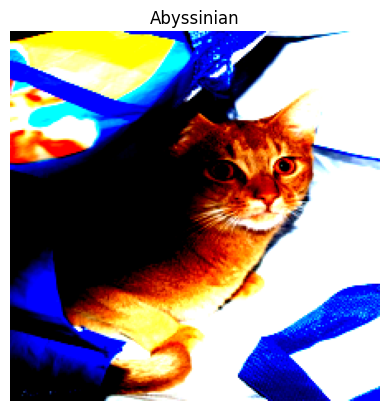

In [ ]:
# Pipeline de pré-processamento das imagens:
# - Resize: todas as arquiteturas pré-treinadas (AlexNet, ResNet, EfficientNet, ViT) esperam
#   entradas de tamanho fixo; 224x224 é o padrão usado no treinamento original desses modelos.
# - ToTensor: converte a imagem PIL (0-255) em tensor float (0-1) no formato [C, H, W].
# - Normalize: usa média e desvio padrão do ImageNet, pois os modelos foram pré-treinados
#   nesse dataset e esperam entradas normalizadas com essas mesmas estatísticas.

from torchvision.datasets import OxfordIIITPet
from torchvision import transforms
import matplotlib.pyplot as plt

transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

dataset = OxfordIIITPet(
    root="data",
    split="trainval",
    target_types="category",
    transform=transform,
    download=True
)

print(f"Número de imagens: {len(dataset)}")
print(f"Número de classes: {len(dataset.classes)}")
print(dataset.classes)

image, label = dataset[0]

plt.imshow(image.permute(1, 2, 0))
plt.title(dataset.classes[label])
plt.axis("off")
plt.show()

## 3. Divisão em treino / validação / teste

In [ ]:
# Divisão do dataset em treino (70%), validação (15%) e teste (15%).
# manual_seed(42) garante que a divisão seja reprodutível entre execuções.

import torch
from torch.utils.data import random_split

# Para que a divisão seja sempre a mesma
torch.manual_seed(42)

train_size = int(0.70 * len(dataset))
val_size = int(0.15 * len(dataset))
test_size = len(dataset) - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size]
)

print(f"Treino: {len(train_dataset)}")
print(f"Validação: {len(val_dataset)}")
print(f"Teste: {len(test_dataset)}")

Treino: 2576
Validação: 552
Teste: 552


## 4. DataLoaders

In [ ]:
# DataLoaders responsáveis por entregar os dados em lotes (batches) durante o treino/avaliação.
# BATCH_SIZE=32: tamanho de lote moderado, bom equilíbrio entre velocidade e uso de memória.
# shuffle=True no treino: embaralha os dados a cada época, evitando que o modelo aprenda
# alguma ordem espúria presente no dataset.
# shuffle=False em val/teste: não é necessário embaralhar, já que não há atualização de pesos.

from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

## 5. Conferência rápida de um batch

In [ ]:
# Pega um único batch do train_loader só para conferir se as dimensões estão corretas.
# Esperado: images.shape = [BATCH_SIZE, 3, 224, 224] e labels.shape = [BATCH_SIZE]

images, labels = next(iter(train_loader))

print("Formato das imagens:", images.shape)
print("Formato dos rótulos:", labels.shape)
print("Primeiros rótulos:", labels)

Formato das imagens: torch.Size([32, 3, 224, 224])
Formato dos rótulos: torch.Size([32])
Primeiros rótulos: tensor([36, 35, 20, 33, 27,  0, 26, 29,  1, 34, 31, 18, 32,  7, 22, 14, 29,  8,
        10, 20, 14,  2, 30,  3, 14, 25,  7, 32,  1, 18, 26, 12])


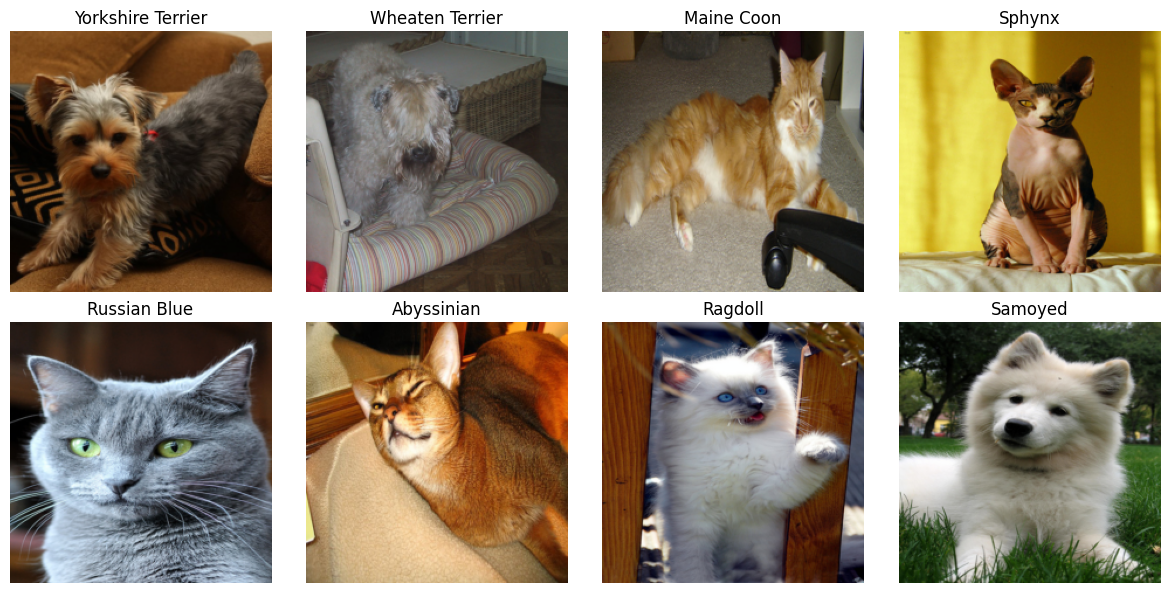

In [ ]:
# Visualização de algumas imagens do batch com seus respectivos rótulos (raças),
# apenas para inspeção visual e garantir que o pré-processamento não corrompeu as imagens.

import matplotlib.pyplot as plt
import numpy as np

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image = images[i].permute(1, 2, 0).numpy()
    image = std * image + mean          # desnormaliza (reverte o Normalize do transform)
    image = np.clip(image, 0, 1)        # garante range válido [0,1] para o imshow
    ax.imshow(image)
    ax.set_title(dataset.classes[labels[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()

## 6. Imports do PyTorch para modelagem e definição do device

In [ ]:
# Imports principais para construção e treinamento dos modelos:
# nn -> camadas e funções de perda; optim -> otimizadores; models -> arquiteturas pré-treinadas

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

In [ ]:
# Define o dispositivo de execução: usa GPU (cuda) se disponível, senão cai para CPU.
# Treinar essas redes (mesmo só a última camada) é bem mais rápido em GPU.

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


## 7. Função para criar o modelo (Transfer Learning)

Aqui é definida a função `get_model`, que recebe o nome da arquitetura desejada e devolve
o modelo pronto para fine-tuning, com a camada final adaptada ao número de classes do
nosso problema (raças de gatos/pets).

**Ideia do transfer learning:** carregar os pesos pré-treinados no ImageNet,
**congelar** os parâmetros do extrator de features (`requires_grad = False`) e treinar
apenas a última camada totalmente conectada (classificador), que é substituída para ter
`num_classes` saídas em vez das 1000 classes originais do ImageNet.


In [ ]:
def get_model(model_name, num_classes):

    if model_name == "alexnet":

        model = models.alexnet(
            weights=models.AlexNet_Weights.DEFAULT
        )

        # Congela apenas as convoluções
        for param in model.features.parameters():
            param.requires_grad = False

        model.classifier[6] = nn.Linear(
            model.classifier[6].in_features,
            num_classes
        )

    elif model_name == "resnet50":

        model = models.resnet50(
            weights=models.ResNet50_Weights.DEFAULT
        )

        # Congela toda a rede
        for param in model.parameters():
            param.requires_grad = False

        # Libera apenas a última camada
        model.fc = nn.Linear(
            model.fc.in_features,
            num_classes
        )

    elif model_name == "efficientnet":

        model = models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.DEFAULT
        )

        # Congela somente o backbone
        for param in model.features.parameters():
            param.requires_grad = False

        model.classifier[1] = nn.Linear(
            model.classifier[1].in_features,
            num_classes
        )

    elif model_name == "vit":

        model = models.vit_b_16(
            weights=models.ViT_B_16_Weights.DEFAULT
        )

        # Congela todo o transformer
        for param in model.parameters():
            param.requires_grad = False

        model.heads.head = nn.Linear(
            model.heads.head.in_features,
            num_classes
        )

    else:
        raise ValueError("Modelo inválido")

    return model

## 8. Função de treinamento

A função `train_model` implementa o laço de treinamento clássico em PyTorch: para cada
época, percorre o `train_loader` fazendo forward + backward + atualização dos pesos, e
em seguida avalia o modelo no `val_loader` (sem calcular gradientes). Ao final, salva em
disco os pesos do melhor modelo (maior acurácia de validação) encontrado durante o treino.


In [ ]:
from tqdm import tqdm

def train_model(model, train_loader, val_loader, epochs, device):

    # CrossEntropyLoss: função de perda padrão para classificação multi-classe
    # (já aplica softmax internamente, por isso a rede não precisa de softmax na saída).
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    best_acc = 0

    for epoch in range(epochs):

        # Treino
        model.train()

        correct = 0
        total = 0
        train_loss = 0

        for images, labels in tqdm(train_loader):

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            train_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_acc = correct / total

        # Validação
        model.eval()

        correct = 0
        total = 0
        val_loss = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                loss = criterion(outputs, labels)

                val_loss += loss.item()

                _, predicted = torch.max(outputs, 1)

                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        val_acc = correct / total

        print(f"Época {epoch+1}/{epochs}")
        print(f"Train Acc: {train_acc:.4f}")
        print(f"Val Acc: {val_acc:.4f}")
        print("-"*40)

        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), f"best_{type(model).__name__}.pth")

    return best_acc

## 9. Treinamento e comparação dos 4 modelos

Laço principal do experimento: para cada arquitetura em `model_names`, cria o modelo
(via `get_model`), treina por 10 épocas e guarda a melhor acurácia de validação obtida
em `results`, para comparação final entre AlexNet, ResNet50, EfficientNet-B0 e ViT.

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

num_classes = len(dataset.classes)

model_names = [
    "alexnet",
    "resnet50",
    "efficientnet",
    "vit"
]

results = {}

for model_name in model_names:

    print("="*60)
    print(f"Treinando {model_name}")
    print("="*60)

    model = get_model(model_name, num_classes).to(device)

    best_acc = train_model(
        model,
        train_loader,
        val_loader,
        epochs=10,
        device=device
    )

    results[model_name] = best_acc

Treinando alexnet
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 148MB/s]
100%|██████████| 81/81 [00:24<00:00,  3.34it/s]


Época 1/10
Train Acc: 0.4429
Val Acc: 0.5870
----------------------------------------


100%|██████████| 81/81 [00:12<00:00,  6.49it/s]


Época 2/10
Train Acc: 0.6557
Val Acc: 0.6304
----------------------------------------


...

Época 8/10
Train Acc: 0.9961
Val Acc: 0.9293
----------------------------------------


100%|██████████| 81/81 [00:35<00:00,  2.28it/s]


Época 9/10
Train Acc: 0.9969
Val Acc: 0.9239
----------------------------------------


100%|██████████| 81/81 [00:35<00:00,  2.27it/s]


Época 10/10
Train Acc: 0.9988
Val Acc: 0.9293
----------------------------------------


## 10. Conferência da arquitetura do classificador (debug)

In [ ]:
# Cria uma instância "crua" da AlexNet só para inspecionar a estrutura do classificador
# (model.classifier) e confirmar visualmente qual camada foi substituída em get_model().
# Não é usada no treinamento — serve apenas para debug/documentação da arquitetura.

model = get_model("alexnet", num_classes)

print(model.classifier)

Sequential(
  (0): Dropout(p=0.5, inplace=False)
  (1): Linear(in_features=9216, out_features=4096, bias=True)
  (2): ReLU(inplace=True)
  (3): Dropout(p=0.5, inplace=False)
  (4): Linear(in_features=4096, out_features=4096, bias=True)
  (5): ReLU(inplace=True)
  (6): Linear(in_features=4096, out_features=37, bias=True)
)


## 11. Resultado final: comparação entre as arquiteturas

In [ ]:
# Exibe a melhor acurácia de validação obtida por cada arquitetura, permitindo
# comparar diretamente qual modelo teve o melhor desempenho na tarefa de classificação
# de raças. Esse resultado é o principal insumo para a seção de resultados do relatório/artigo.

print("\nResultados finais:")

for model_name, acc in results.items():
    print(f"{model_name}: {acc:.4f}")


Resultados finais:
alexnet: 0.6667
resnet50: 0.9330
efficientnet: 0.8605
vit: 0.9293


## 12. Análise: congelamento total vs. parcial vs. nenhum

Nas seções anteriores, cada arquitetura usou uma estratégia de congelamento fixa
(ex.: ResNet50 e ViT com todo o backbone congelado, treinando só a camada final).
Aqui comparamos, para as **mesmas 4 arquiteturas**, três regimes diferentes de
congelamento de camadas:

- **`total`** — todo o backbone pré-treinado fica congelado; só a camada final
  (classificador) é treinada. É o regime mais rápido e mais "conservador" em
  relação aos pesos pré-treinados.
- **`parcial`** — a maior parte do backbone continua congelada, mas o(s)
  último(s) bloco(s) (mais próximos da saída) e a camada final são liberados
  para treino. Ideia: camadas iniciais aprendem features genéricas (bordas,
  texturas) que servem para qualquer imagem; camadas finais são mais
  específicas à tarefa original (ImageNet) e se beneficiam de reajuste fino
  para o novo domínio (raças de gatos/pets).
- **`nenhum`** — nenhuma camada é congelada; a rede inteira é ajustada
  (fine-tuning completo). Tende a ser o mais lento e o mais suscetível a
  overfitting com poucos dados, mas também o que tem mais liberdade para se
  adaptar ao novo problema.

Para cada combinação (arquitetura × regime de congelamento) medimos:
1. a **melhor acurácia de validação**;
2. o **percentual de parâmetros treináveis** (proxy do custo computacional);
3. o **tempo total de treino**.


In [ ]:
import time

def get_head(model, model_name):
    """Retorna o módulo correspondente à camada final (classificador) de cada arquitetura."""
    if model_name == "alexnet":
        return model.classifier[6]
    elif model_name == "resnet50":
        return model.fc
    elif model_name == "efficientnet":
        return model.classifier[1]
    elif model_name == "vit":
        return model.heads.head
    else:
        raise ValueError("Modelo inválido")


def get_backbone_tail(model, model_name):
    """
    Retorna o(s) último(s) bloco(s) do backbone de cada arquitetura, usados no
    congelamento PARCIAL: essas camadas ficam treináveis (mais específicas ao
    dataset original), enquanto o restante do backbone permanece congelado
    (features mais genéricas, tipo bordas e texturas).
    """
    if model_name == "alexnet":
        return model.features[8:]        # últimas convoluções da AlexNet
    elif model_name == "resnet50":
        return model.layer4               # último bloco residual
    elif model_name == "efficientnet":
        return model.features[-2:]        # últimos blocos MBConv
    elif model_name == "vit":
        return model.encoder.layers[-1]   # último bloco do transformer
    else:
        raise ValueError("Modelo inválido")


def build_base_model(model_name, num_classes):
    """Cria o modelo pré-treinado com a camada final já adaptada, sem aplicar congelamento."""
    if model_name == "alexnet":
        model = models.alexnet(weights=models.AlexNet_Weights.DEFAULT)
        model.classifier[6] = nn.Linear(model.classifier[6].in_features, num_classes)

    elif model_name == "resnet50":
        model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        model.fc = nn.Linear(model.fc.in_features, num_classes)

    elif model_name == "efficientnet":
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)

    elif model_name == "vit":
        model = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)
        model.heads.head = nn.Linear(model.heads.head.in_features, num_classes)

    else:
        raise ValueError("Modelo inválido")

    return model


def apply_freeze(model, model_name, freeze_mode):
    """
    Aplica um dos 3 regimes de congelamento:
      - "total":   congela TODO o backbone, treina só a camada final.
      - "parcial": congela a maior parte do backbone, mas libera o(s) último(s)
                   bloco(s) + a camada final.
      - "nenhum":  não congela nada -> fine-tuning completo da rede pré-treinada.
    """
    if freeze_mode == "nenhum":
        for p in model.parameters():
            p.requires_grad = True
        return model

    # Para "total" e "parcial" começamos congelando tudo
    for p in model.parameters():
        p.requires_grad = False

    # A camada final é sempre treinável (é ela que aprende as classes novas)
    for p in get_head(model, model_name).parameters():
        p.requires_grad = True

    if freeze_mode == "parcial":
        for p in get_backbone_tail(model, model_name).parameters():
            p.requires_grad = True

    return model


def get_model_freeze(model_name, num_classes, freeze_mode):
    model = build_base_model(model_name, num_classes)
    model = apply_freeze(model, model_name, freeze_mode)
    return model


def count_trainable_params(model):
    """Retorna (nº parâmetros treináveis, nº parâmetros totais, % treinável)."""
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total, 100 * trainable / total


### 12.1 Função de treino com medição de tempo

Reaproveita a mesma lógica de treino da seção 8, mas:
- passa ao otimizador apenas os parâmetros com `requires_grad=True` (evita
  desperdiçar memória/estado do Adam em parâmetros congelados);
- mede o tempo total de treino, já que esse é justamente um dos efeitos que
  queremos observar ao comparar os regimes de congelamento.


In [ ]:
def train_model_freeze(model, train_loader, val_loader, epochs, device, checkpoint_path=None):
    """
    checkpoint_path: se informado, salva o state_dict do melhor modelo (maior
    val_acc) nesse caminho. Usamos um nome unico por (modelo, congelamento)
    para nao sobrescrever os pesos entre combinacoes -- isso e o que permite
    recarregar cada um dos 12 modelos depois, na secao 13, sem retreinar.
    """

    criterion = nn.CrossEntropyLoss()

    # So os parametros treinaveis vao para o otimizador
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = optim.Adam(trainable_params, lr=0.001)

    best_acc = 0
    start_time = time.time()

    for epoch in range(epochs):

        # Treino
        model.train()
        correct, total, train_loss = 0, 0, 0

        for images, labels in tqdm(train_loader, leave=False):
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_acc = correct / total

        # Validacao
        model.eval()
        correct, total, val_loss = 0, 0, 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                _, predicted = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        val_acc = correct / total

        print(f"Epoca {epoch+1}/{epochs} | Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")

        if val_acc > best_acc:
            best_acc = val_acc
            if checkpoint_path is not None:
                torch.save(model.state_dict(), checkpoint_path)

    elapsed = time.time() - start_time
    return best_acc, elapsed


### 12.2 Treinamento comparativo (4 arquiteturas × 3 regimes de congelamento)

Roda as 4 arquiteturas (`alexnet`, `resnet50`, `efficientnet`, `vit`) para cada
um dos 3 regimes de congelamento, totalizando 12 treinos. Usamos
`FREEZE_EPOCHS = 5` (menos que as 10 épocas da seção 9) para viabilizar rodar
todas as combinações em tempo razoável — ajuste esse valor se quiser resultados
mais precisos.


In [ ]:
freeze_modes = ["total", "parcial", "nenhum"]

FREEZE_EPOCHS = 5  # reduzido em relacao as 10 epocas da secao 9, para viabilizar
                    # 4 modelos x 3 regimes de congelamento (12 treinos no total)

CHECKPOINT_DIR = "checkpoints_freeze"
import os
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

freeze_results = []  # lista de dicts -> vira um DataFrame na secao 12.3

for model_name in model_names:
    for freeze_mode in freeze_modes:

        print("="*60)
        print(f"Modelo: {model_name} | Congelamento: {freeze_mode}")
        print("="*60)

        model = get_model_freeze(model_name, num_classes, freeze_mode).to(device)

        trainable, total_params, pct_trainable = count_trainable_params(model)
        print(f"Parametros treinaveis: {trainable:,} / {total_params:,} ({pct_trainable:.2f}%)")

        checkpoint_path = os.path.join(CHECKPOINT_DIR, f"{model_name}_{freeze_mode}.pth")

        best_acc, elapsed = train_model_freeze(
            model,
            train_loader,
            val_loader,
            epochs=FREEZE_EPOCHS,
            device=device,
            checkpoint_path=checkpoint_path
        )

        freeze_results.append({
            "modelo": model_name,
            "congelamento": freeze_mode,
            "melhor_val_acc": best_acc,
            "pct_parametros_treinaveis": pct_trainable,
            "tempo_treino_s": elapsed,
            "checkpoint_path": checkpoint_path
        })


Modelo: alexnet | Congelamento: total
Parametros treinaveis: 151,589 / 57,155,429 (0.27%)


Epoca 1/5 | Train Acc: 0.5908 | Val Acc: 0.6685


Epoca 2/5 | Train Acc: 0.8785 | Val Acc: 0.7355


Epoca 3/5 | Train Acc: 0.9379 | Val Acc: 0.7627


Epoca 4/5 | Train Acc: 0.9596 | Val Acc: 0.7645


...

Epoca 1/5 | Train Acc: 0.0252 | Val Acc: 0.0254


Epoca 2/5 | Train Acc: 0.0357 | Val Acc: 0.0290


Epoca 3/5 | Train Acc: 0.0435 | Val Acc: 0.0308


Epoca 4/5 | Train Acc: 0.0536 | Val Acc: 0.0471


Epoca 5/5 | Train Acc: 0.0633 | Val Acc: 0.0707


### 12.3 Tabela comparativa


In [ ]:
import pandas as pd

df_freeze = pd.DataFrame(freeze_results)
df_freeze = df_freeze.sort_values(["modelo", "congelamento"]).reset_index(drop=True)
df_freeze


,modelo,congelamento,melhor_val_acc,pct_parametros_treinaveis,tempo_treino_s,checkpoint_path
0,alexnet,nenhum,0.019928,100.000000,75.665025,checkpoints_freeze/alexnet_nenhum.pth
1,alexnet,parcial,0.711957,2.846031,74.976617,checkpoints_freeze/alexnet_parcial.pth
2,alexnet,total,0.764493,0.265222,74.007039,checkpoints_freeze/alexnet_total.pth
3,efficientnet,nenhum,0.820652,100.000000,91.262096,checkpoints_freeze/efficientnet_nenhum.pth
4,efficientnet,parcial,0.875000,29.021084,77.813507,checkpoints_freeze/efficientnet_parcial.pth
5,efficientnet,total,0.858696,1.168869,78.166323,checkpoints_freeze/efficientnet_total.pth
6,resnet50,nenhum,0.759058,100.000000,147.385509,checkpoints_freeze/resnet50_nenhum.pth
7,resnet50,parcial,0.900362,63.774796,90.708575,checkpoints_freeze/resnet50_parcial.pth
8,resnet50,total,0.927536,0.321462,85.016950,checkpoints_freeze/resnet50_total.pth
9,vit,nenhum,0.070652,100.000000,487.971127,checkpoints_freeze/vit_nenhum.pth


### 12.4 Acurácia por arquitetura e regime de congelamento


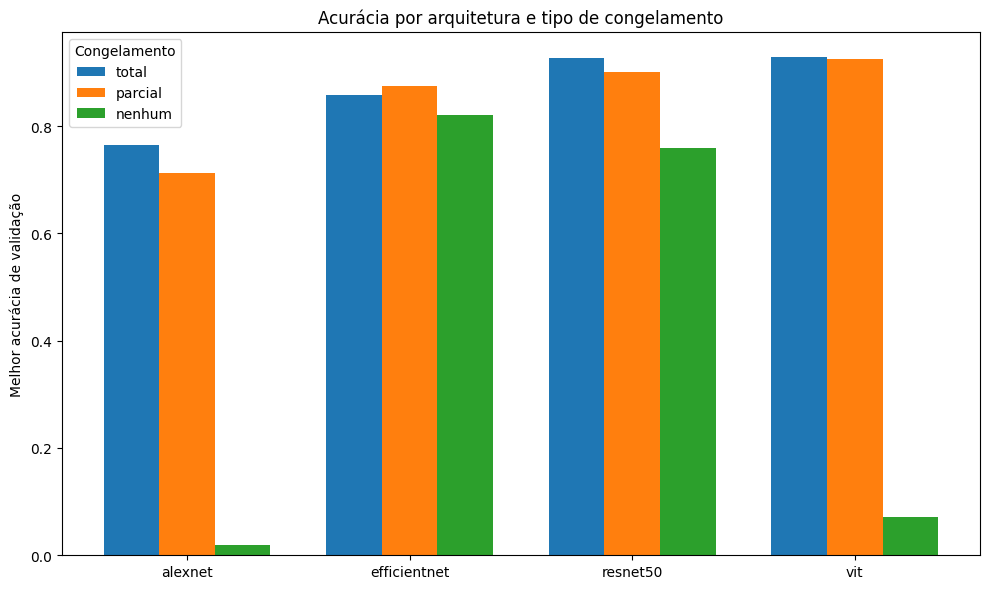

In [ ]:
import numpy as np

pivot_acc = df_freeze.pivot(index="modelo", columns="congelamento", values="melhor_val_acc")
pivot_acc = pivot_acc[["total", "parcial", "nenhum"]]  # ordem fixa nas barras

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(pivot_acc.index))
width = 0.25

for i, modo in enumerate(pivot_acc.columns):
    ax.bar(x + i * width, pivot_acc[modo], width, label=modo)

ax.set_xticks(x + width)
ax.set_xticklabels(pivot_acc.index)
ax.set_ylabel("Melhor acurácia de validação")
ax.set_title("Acurácia por arquitetura e tipo de congelamento")
ax.legend(title="Congelamento")
plt.tight_layout()
plt.show()


### 12.5 Custo computacional: % de parâmetros treináveis e tempo de treino

Enquanto o gráfico anterior mostra o efeito na acurácia, aqui olhamos o
"preço" de cada regime: quanto menos parâmetros treináveis, menor tende a ser
o tempo de treino — mas isso também pode limitar o quanto o modelo consegue
se adaptar ao novo domínio.


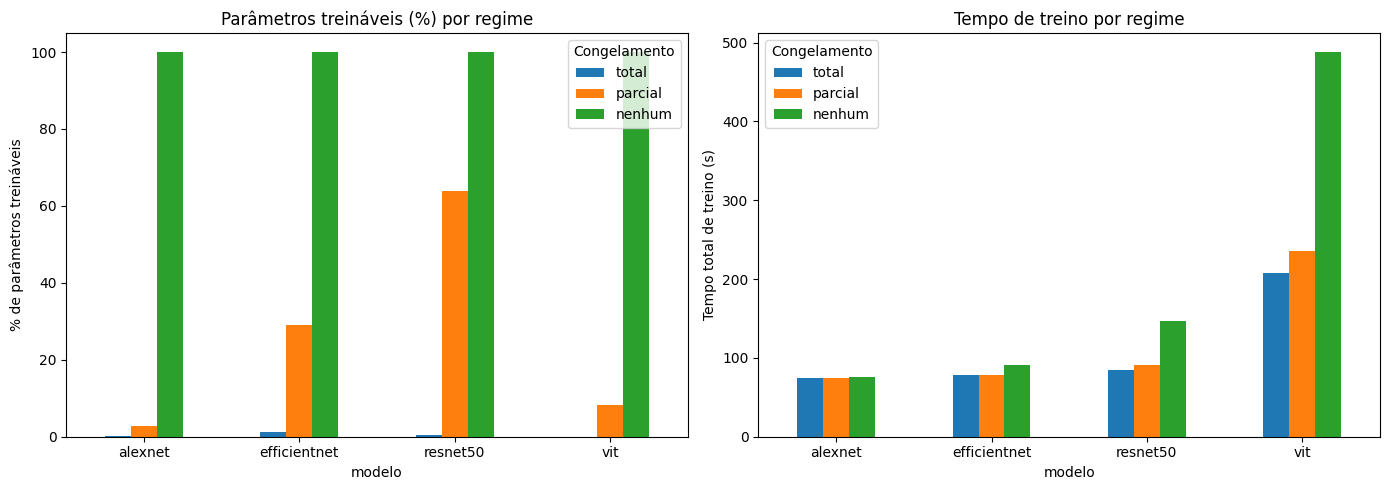

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# % de parâmetros treináveis por modelo/regime
pivot_pct = df_freeze.pivot(index="modelo", columns="congelamento", values="pct_parametros_treinaveis")
pivot_pct = pivot_pct[["total", "parcial", "nenhum"]]
pivot_pct.plot(kind="bar", ax=axes[0])
axes[0].set_ylabel("% de parâmetros treináveis")
axes[0].set_title("Parâmetros treináveis (%) por regime")
axes[0].legend(title="Congelamento")
axes[0].tick_params(axis="x", rotation=0)

# Tempo total de treino por modelo/regime
pivot_time = df_freeze.pivot(index="modelo", columns="congelamento", values="tempo_treino_s")
pivot_time = pivot_time[["total", "parcial", "nenhum"]]
pivot_time.plot(kind="bar", ax=axes[1])
axes[1].set_ylabel("Tempo total de treino (s)")
axes[1].set_title("Tempo de treino por regime")
axes[1].legend(title="Congelamento")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


### 12.6 Discussão

Pontos a observar nos resultados obtidos acima (preencha após rodar):

- **Congelamento total vs. nenhum**: o fine-tuning completo (`nenhum`) tende a
  usar bem mais tempo de treino e memória, mas nem sempre resulta em maior
  acurácia — principalmente com poucas épocas e um dataset relativamente
  pequeno, onde há risco de overfitting ou de "desaprender" pesos úteis do
  pré-treino.
- **Congelamento parcial**: geralmente representa um bom equilíbrio, liberando
  só as camadas finais do backbone (mais específicas à tarefa original) para
  se ajustarem ao novo domínio, mantendo baixo o custo computacional.
- **Diferenças entre arquiteturas**: modelos maiores/mais profundos (ex. ViT)
  tendem a sofrer mais com fine-tuning completo em poucos dados/poucas épocas,
  enquanto arquiteturas menores (ex. AlexNet) podem se beneficiar mais de
  liberar mais parâmetros, já que têm menos capacidade "genérica" herdada do
  pré-treino.


## 13. Matrizes de confusão e comparações entre os modelos

Até aqui só olhamos acurácia agregada. Nesta seção usamos o **conjunto de
teste** (`test_dataset` criado na seção 3, e `test_loader` montado na seção 4,
ainda não usado até aqui) para os 12 modelos treinados na seção 12, e fazemos
3 tipos de comparação:

1. **Matriz de confusão** por arquitetura (melhor regime de congelamento de
   cada uma) — mostra quais raças o modelo confunde entre si.
2. **Dificuldade por classe** — quais raças são difíceis para todos os
   modelos vs. difíceis só para alguns.
3. **Overlap de erros entre arquiteturas** — quantas imagens todos os modelos
   erram, quantas só um modelo erra, etc. — e um **ranking geral** juntando
   acurácia de teste, F1-macro, % de parâmetros treináveis e tempo de treino.

Isso reaproveita os checkpoints salvos em `checkpoints_freeze/` na seção 12
(um arquivo por combinação modelo × congelamento), então não é necessário
retreinar nada aqui.


### 13.1 Avaliando os 12 modelos no conjunto de teste

In [ ]:
from sklearn.metrics import f1_score, classification_report
import numpy as np

def evaluate_on_test(model, test_loader, device):
    """Roda o modelo no test_loader e retorna (y_true, y_pred) como arrays numpy."""
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            y_true.extend(labels.numpy().tolist())
            y_pred.extend(predicted.cpu().numpy().tolist())

    return np.array(y_true), np.array(y_pred)


In [ ]:
class_names = dataset.classes

test_predictions = {}   # (modelo, congelamento) -> (y_true, y_pred)
test_metrics = []

for row in freeze_results:
    model_name = row["modelo"]
    freeze_mode = row["congelamento"]
    checkpoint_path = row["checkpoint_path"]

    model = get_model_freeze(model_name, num_classes, freeze_mode).to(device)
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))

    y_true, y_pred = evaluate_on_test(model, test_loader, device)
    test_predictions[(model_name, freeze_mode)] = (y_true, y_pred)

    test_acc = (y_true == y_pred).mean()
    test_f1_macro = f1_score(y_true, y_pred, average="macro")

    test_metrics.append({
        "modelo": model_name,
        "congelamento": freeze_mode,
        "test_acc": test_acc,
        "test_f1_macro": test_f1_macro,
        "pct_parametros_treinaveis": row["pct_parametros_treinaveis"],
        "tempo_treino_s": row["tempo_treino_s"]
    })

    print(f"{model_name:12s} | {freeze_mode:8s} | Test Acc: {test_acc:.4f} | F1-macro: {test_f1_macro:.4f}")

df_test = pd.DataFrame(test_metrics)


alexnet      | total    | Test Acc: 0.7572 | F1-macro: 0.7468
alexnet      | parcial  | Test Acc: 0.7228 | F1-macro: 0.7134
alexnet      | nenhum   | Test Acc: 0.0236 | F1-macro: 0.0012
resnet50     | total    | Test Acc: 0.8986 | F1-macro: 0.8916
resnet50     | parcial  | Test Acc: 0.9149 | F1-macro: 0.9121
resnet50     | nenhum   | Test Acc: 0.7518 | F1-macro: 0.7274
efficientnet | total    | Test Acc: 0.8333 | F1-macro: 0.8224
efficientnet | parcial  | Test Acc: 0.8605 | F1-macro: 0.8554
efficientnet | nenhum   | Test Acc: 0.8080 | F1-macro: 0.8030
vit          | total    | Test Acc: 0.9293 | F1-macro: 0.9270
vit          | parcial  | Test Acc: 0.9402 | F1-macro: 0.9370
vit          | nenhum   | Test Acc: 0.0707 | F1-macro: 0.0471


### 13.2 Matriz de confusão (melhor regime de cada arquitetura)

Para não gerar 12 matrizes 37×37 (uma para cada combinação), plotamos a
matriz de confusão apenas do **melhor regime de congelamento de cada
arquitetura** (segundo a acurácia de teste). Se quiser ver alguma combinação
específica, basta trocar a chave usada em `test_predictions[...]`.


          modelo congelamento  test_acc  test_f1_macro  \
0        alexnet        total  0.757246       0.746834   
7   efficientnet      parcial  0.860507       0.855372   
4       resnet50      parcial  0.914855       0.912145   
10           vit      parcial  0.940217       0.936988   

    pct_parametros_treinaveis  tempo_treino_s  
0                    0.265222       74.007039  
7                   29.021084       77.813507  
4                   63.774796       90.708575  
10                   8.291465      235.525481  


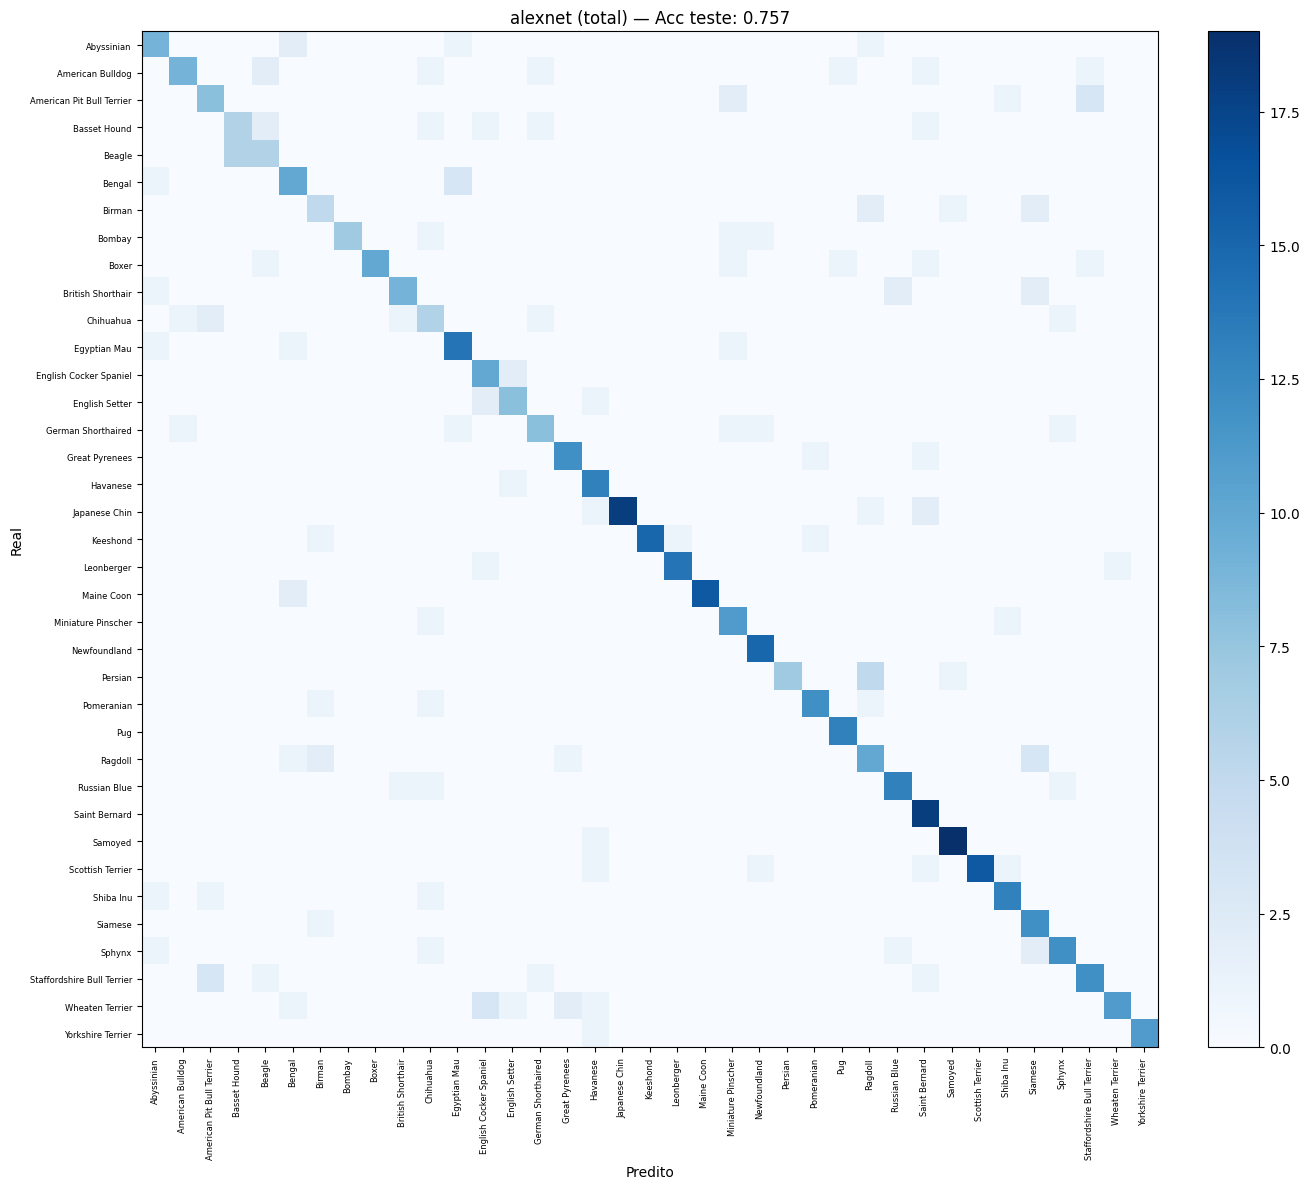

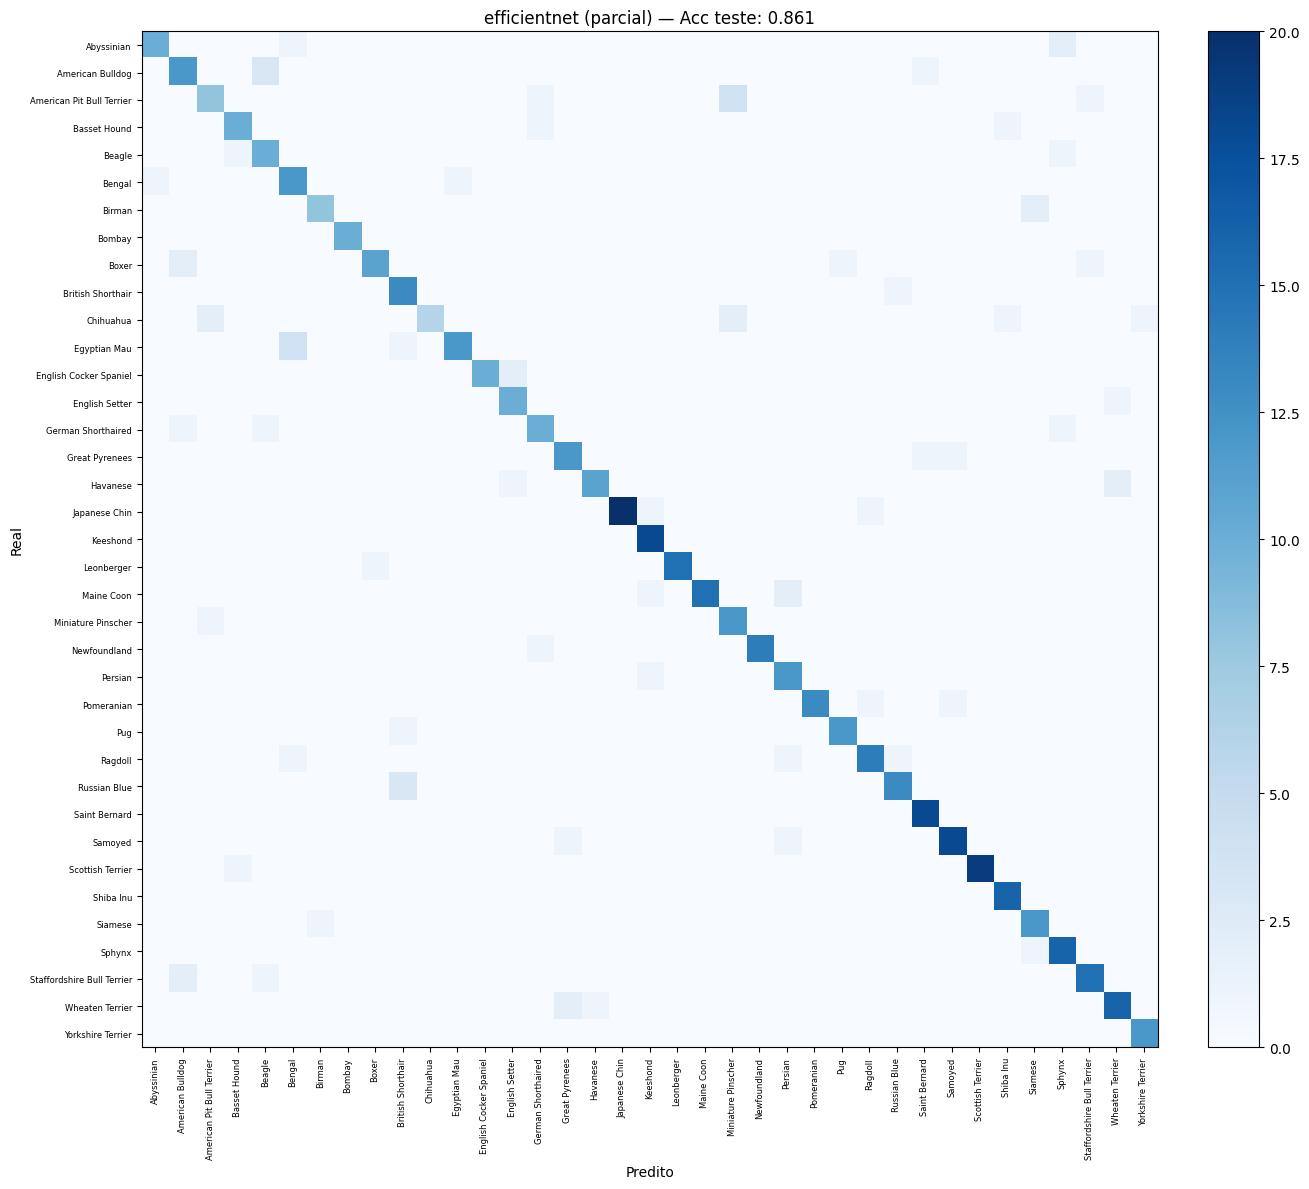

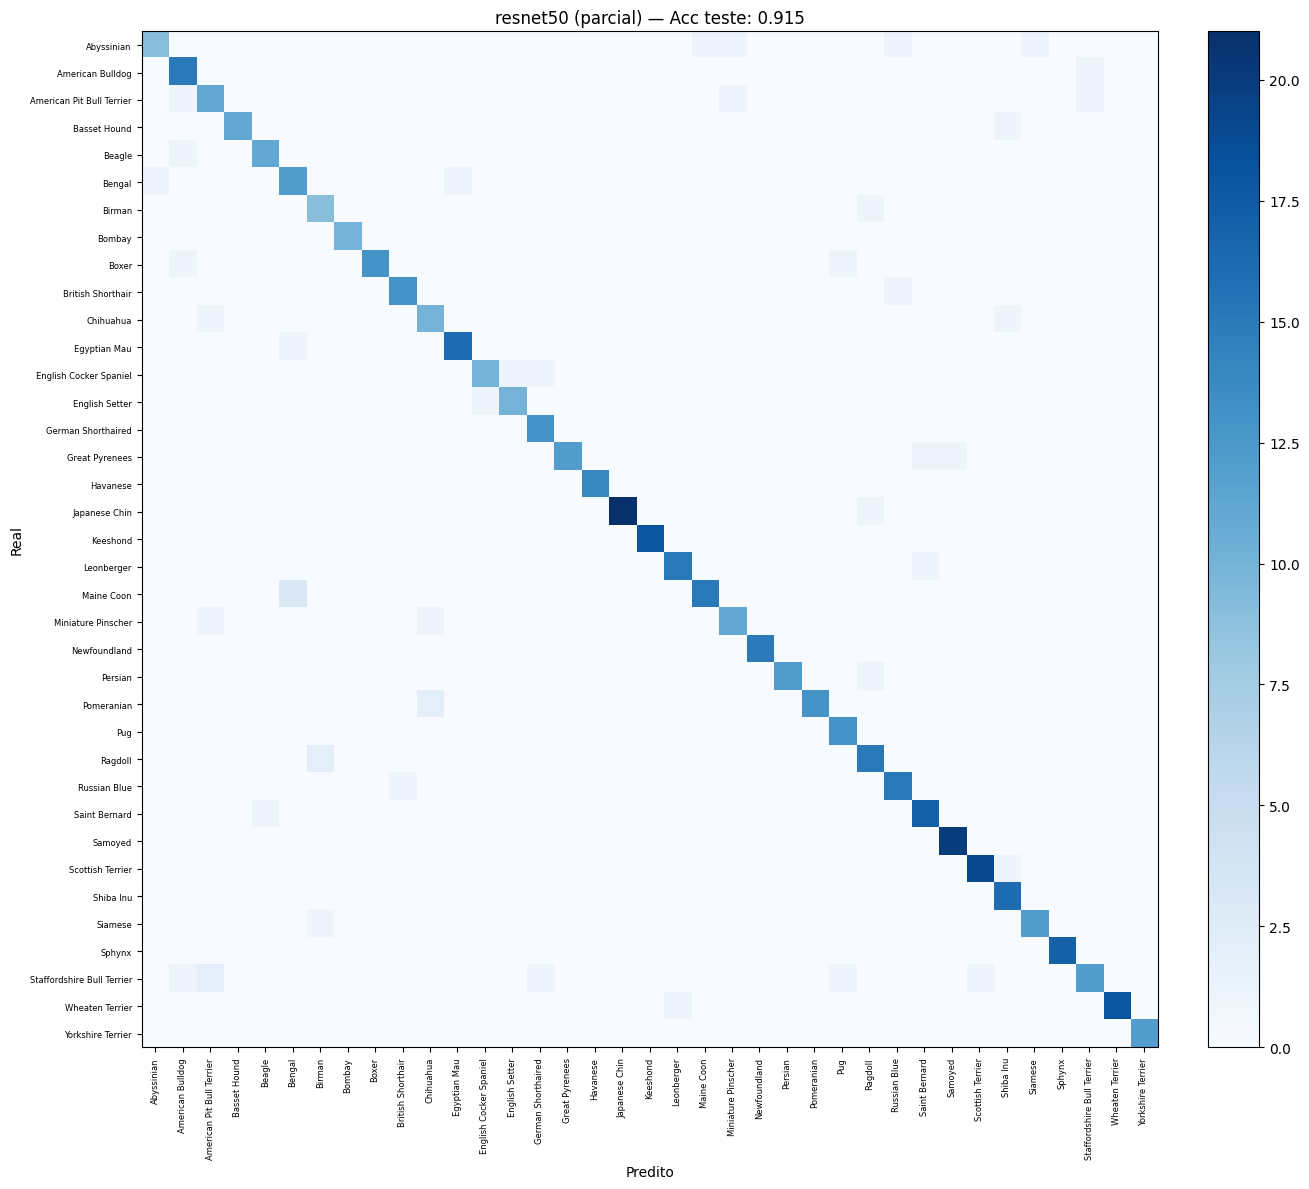

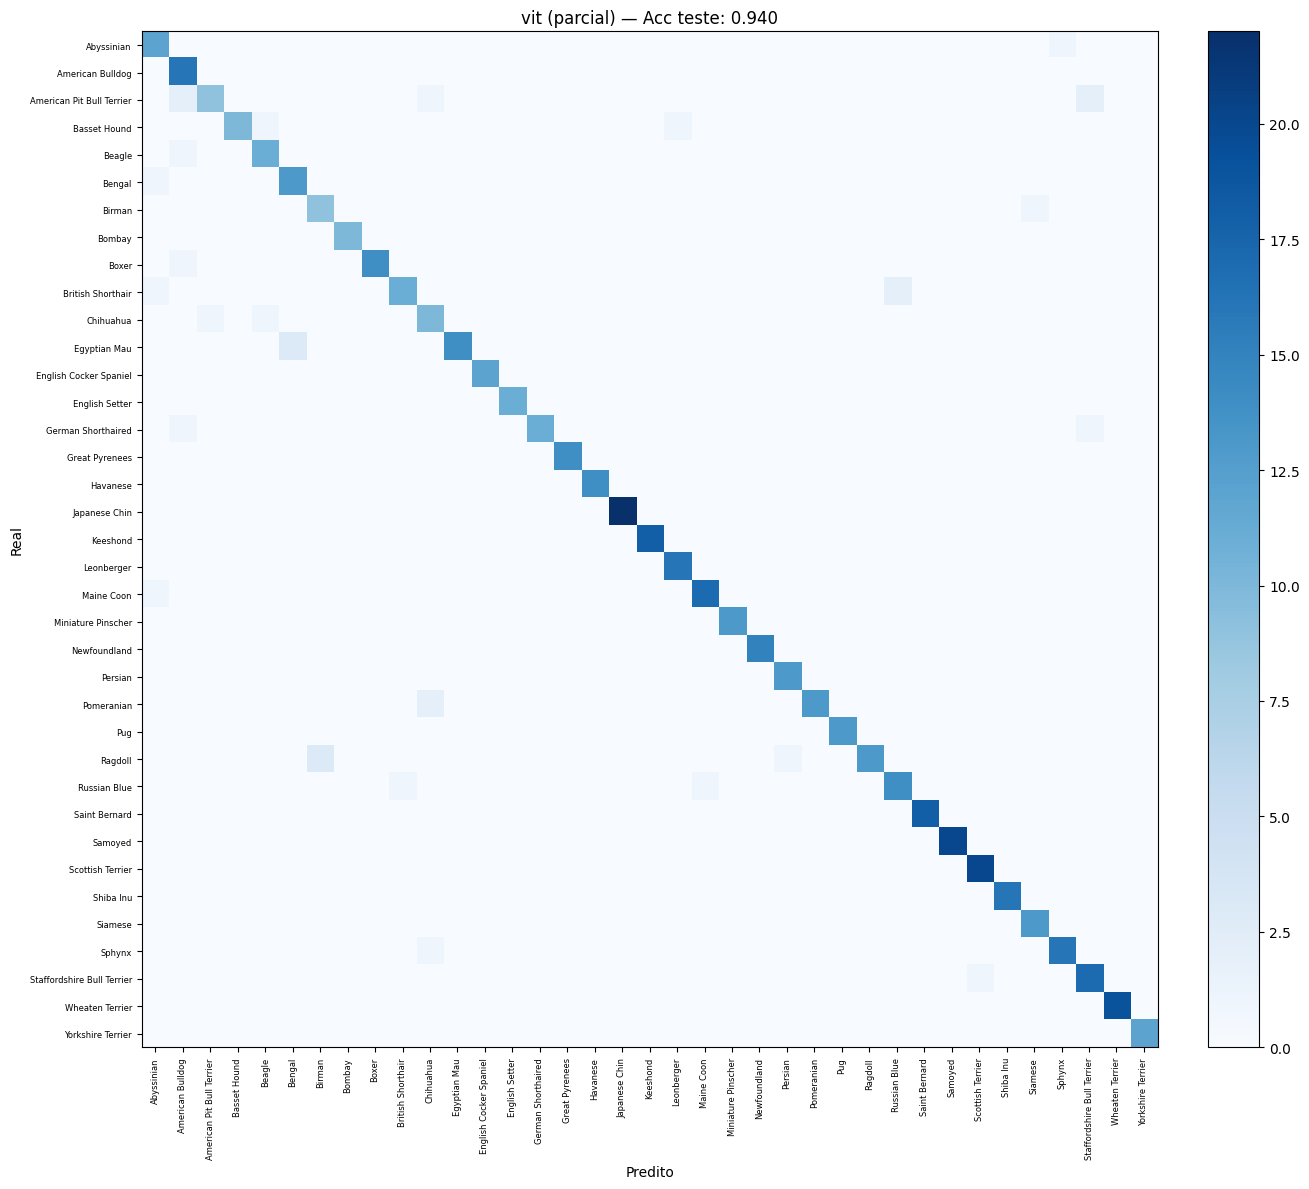

In [ ]:
def plot_confusion_matrix(y_true, y_pred, class_names, title):
    cm = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))

    fig, ax = plt.subplots(figsize=(14, 12))
    im = ax.imshow(cm, cmap="Blues")

    ax.set_xticks(range(len(class_names)))
    ax.set_yticks(range(len(class_names)))
    ax.set_xticklabels(class_names, rotation=90, fontsize=6)
    ax.set_yticklabels(class_names, fontsize=6)
    ax.set_xlabel("Predito")
    ax.set_ylabel("Real")
    ax.set_title(title)

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()


from sklearn.metrics import confusion_matrix

# Melhor regime de congelamento por arquitetura, segundo acurácia de teste
best_per_model = df_test.loc[df_test.groupby("modelo")["test_acc"].idxmax()]
print(best_per_model)

for _, row in best_per_model.iterrows():
    y_true, y_pred = test_predictions[(row["modelo"], row["congelamento"])]
    plot_confusion_matrix(
        y_true, y_pred, class_names,
        title=f"{row['modelo']} ({row['congelamento']}) — Acc teste: {row['test_acc']:.3f}"
    )


### 13.3 Quais classes são mais difíceis (para todos os modelos ou só para alguns)?

Calculamos o F1 por classe para cada uma das 12 combinações e comparamos:
- **F1 médio da classe entre todos os modelos** → raças estruturalmente
  difíceis (provavelmente parecidas com outras raças, ex. gatos de pelagem
  semelhante).
- **Desvio-padrão do F1 da classe entre os modelos** → raças em que o
  desempenho varia muito conforme a arquitetura/regime, ou seja, "depende do
  modelo".


In [ ]:
per_class_f1 = {}

for (model_name, freeze_mode), (y_true, y_pred) in test_predictions.items():
    report = classification_report(
        y_true, y_pred,
        labels=range(len(class_names)),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
    col_name = f"{model_name}_{freeze_mode}"
    per_class_f1[col_name] = {cls: report[cls]["f1-score"] for cls in class_names}

df_class_f1 = pd.DataFrame(per_class_f1)
df_class_f1["f1_medio"] = df_class_f1.mean(axis=1)
df_class_f1["f1_desvio"] = df_class_f1.drop(columns=["f1_medio"]).std(axis=1)

print("Classes mais difíceis (menor F1 médio entre todos os modelos):")
print(df_class_f1.sort_values("f1_medio").head(10)[["f1_medio", "f1_desvio"]])

print("\nClasses com desempenho mais inconsistente entre modelos (maior desvio-padrão):")
print(df_class_f1.sort_values("f1_desvio", ascending=False).head(10)[["f1_medio", "f1_desvio"]])


Classes mais difíceis (menor F1 médio entre todos os modelos):
                            f1_medio  f1_desvio
Ragdoll                     0.533768   0.340863
American Pit Bull Terrier   0.553186   0.266314
Beagle                      0.571290   0.327169
Chihuahua                   0.577432   0.267725
Birman                      0.588792   0.305697
American Bulldog            0.597964   0.327321
Staffordshire Bull Terrier  0.610675   0.325411
Bengal                      0.638607   0.307577
Abyssinian                  0.653759   0.290599
Russian Blue                0.655243   0.299474

Classes com desempenho mais inconsistente entre modelos (maior desvio-padrão):
                   f1_medio  f1_desvio
Yorkshire Terrier  0.801590   0.377279
Keeshond           0.800152   0.374961
Japanese Chin      0.798864   0.374569
Pug                0.795949   0.373103
Leonberger         0.779700   0.370858
Scottish Terrier   0.774428   0.366149
Saint Bernard      0.738768   0.359185
Havanese         

### 13.4 Overlap de erros entre arquiteturas

Usando o melhor regime de cada arquitetura (seção 13.2), verificamos, imagem
a imagem do teste, quais modelos acertam e quais erram. Isso separa dois
tipos de erro:

- **Erro universal**: nenhum modelo acerta → provavelmente a imagem/classe é
  intrinsecamente difícil (ambígua, mal rotulada, oclusão, etc.), não um
  problema de uma arquitetura específica.
- **Erro específico**: só uma arquitetura erra enquanto as outras acertam →
  fraqueza pontual daquele modelo/regime, e não do problema em si.


In [ ]:
best_keys = list(zip(best_per_model["modelo"], best_per_model["congelamento"]))

# Todos os y_true das 4 combinações devem ser idênticos (mesmo test_loader,
# sem shuffle) — usamos o primeiro como referência.
y_true_ref = test_predictions[best_keys[0]][0]

correctness = pd.DataFrame({
    f"{m}_{f}": (test_predictions[(m, f)][1] == y_true_ref)
    for (m, f) in best_keys
})

n_models = correctness.shape[1]
acertos_por_imagem = correctness.sum(axis=1)  # 0 = todos erraram, n_models = todos acertaram

print("Distribuição de acertos por imagem (0 = todos erraram, "
      f"{n_models} = todos acertaram):")
print(acertos_por_imagem.value_counts().sort_index())

todos_erraram = (acertos_por_imagem == 0).sum()
todos_acertaram = (acertos_por_imagem == n_models).sum()

print(f"\nImagens que TODOS os modelos erraram: {todos_erraram} "
      f"({100*todos_erraram/len(acertos_por_imagem):.1f}% do teste)")
print(f"Imagens que TODOS os modelos acertaram: {todos_acertaram} "
      f"({100*todos_acertaram/len(acertos_por_imagem):.1f}% do teste)")

# Classes mais presentes nos erros universais
if todos_erraram > 0:
    idx_erro_universal = acertos_por_imagem[acertos_por_imagem == 0].index
    classes_erro_universal = pd.Series(
        [class_names[y_true_ref[i]] for i in idx_erro_universal]
    ).value_counts()
    print("\nRaças mais presentes nos erros universais:")
    print(classes_erro_universal.head(10))


Distribuição de acertos por imagem (0 = todos erraram, 4 = todos acertaram):
0      9
1     16
2     44
3    119
4    364
Name: count, dtype: int64

Imagens que TODOS os modelos erraram: 9 (1.6% do teste)
Imagens que TODOS os modelos acertaram: 364 (65.9% do teste)

Raças mais presentes nos erros universais:
American Pit Bull Terrier    3
Egyptian Mau                 1
Bengal                       1
Chihuahua                    1
Boxer                        1
Abyssinian                   1
Basset Hound                 1
Name: count, dtype: int64


### 13.5 Ranking geral

Junta em uma única tabela: acurácia de teste, F1-macro, % de parâmetros
treináveis e tempo de treino — para comparar diretamente custo × benefício de
cada combinação modelo/congelamento.


In [ ]:
ranking = df_test.sort_values("test_acc", ascending=False).reset_index(drop=True)
ranking.index += 1  # posição no ranking começando em 1
ranking


,modelo,congelamento,test_acc,test_f1_macro,pct_parametros_treinaveis,tempo_treino_s
1,vit,parcial,0.940217,0.936988,8.291465,235.525481
2,vit,total,0.929348,0.926950,0.033152,207.722094
3,resnet50,parcial,0.914855,0.912145,63.774796,90.708575
4,resnet50,total,0.898551,0.891553,0.321462,85.016950
5,efficientnet,parcial,0.860507,0.855372,29.021084,77.813507
6,efficientnet,total,0.833333,0.822431,1.168869,78.166323
7,efficientnet,nenhum,0.807971,0.802951,100.000000,91.262096
8,alexnet,total,0.757246,0.746834,0.265222,74.007039
9,resnet50,nenhum,0.751812,0.727428,100.000000,147.385509
10,alexnet,parcial,0.722826,0.713414,2.846031,74.976617
